# Lab 5: Decision Tree Classifier
## Student Placement Prediction using Scikit-Learn

This notebook demonstrates the end-to-end design, implementation, evaluation, and visual interpretation of a **Decision Tree Classifier** for predicting campus placement outcomes (`Placed` vs. `Not Placed`) on the real-world **Campus Placement Dataset**.

### Laboratory Objectives:
1. Understand feature matrix ($X$) construction and target variable ($y$) identification.
2. Implement robust data hygiene by eliminating non-predictive identifiers (`sl_no`) and preventing target leakage (`salary`).
3. Construct a leak-free preprocessing pipeline using `ColumnTransformer`, `SimpleImputer`, and `OneHotEncoder`.
4. Perform an 80:20 stratified train-test split (`random_state=42`) preserving class ratios.
5. Train a `DecisionTreeClassifier` within a Scikit-Learn `Pipeline`.
6. Evaluate performance across Accuracy, Precision, Recall, F1-Score, Confusion Matrix, and Classification Report.
7. Generate diagnostic visualizations: Confusion Matrix, Decision Tree Structure, and Gini Feature Importance.
8. Analyze the impacts of tree depth, variance/bias tradeoffs, overfitting, and hyperparameter pruning.


---
### 1. Import Essential Libraries and Configure Environment
Import necessary packages from the Python standard library, Pandas, NumPy, Matplotlib, Seaborn, and Scikit-learn. We set relative paths to allow execution seamlessly from both the repository root and the `Lab5/` folder.


In [1]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Display configurations
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 1000)
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")

# Relative path management
DATA_DIR = Path("datasets") if Path("datasets").exists() else Path("../datasets")
OUTPUT_DIR = Path("Lab5/outputs") if Path("Lab5").exists() else Path("outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print(f"Data directory  : {DATA_DIR.resolve()}")
print(f"Output directory: {OUTPUT_DIR.resolve()}")


Data directory  : /home/jeet/Desktop/Artificial_Intelligence/datasets
Output directory: /home/jeet/Desktop/Artificial_Intelligence/Lab5/outputs


---
### 2. Load the Dataset with Relative Path Resolution
Load `Placement_Data_Full_Class.csv` from the shared `datasets/` directory. We verify file existence before loading to avoid silent failures.


In [2]:
dataset_path = DATA_DIR / "Placement_Data_Full_Class.csv"
if not dataset_path.exists():
    raise FileNotFoundError(f"Dataset missing at {dataset_path}. Ensure datasets/Placement_Data_Full_Class.csv is present.")

df = pd.read_csv(dataset_path)
print(f"Dataset successfully loaded from: {dataset_path}")
print(f"Total Rows: {df.shape[0]}, Total Columns: {df.shape[1]}")


Dataset successfully loaded from: ../datasets/Placement_Data_Full_Class.csv
Total Rows: 215, Total Columns: 15


---
### 3. Exploratory Inspection: Head, Tail, Shape, and Columns
Inspect the structural integrity and sample records from the beginning and end of the dataset.


In [3]:
print("--- First 5 Records (head) ---")
display(df.head())

print("--- Last 5 Records (tail) ---")
display(df.tail())

print(f"\nDimensions: {df.shape[0]} rows x {df.shape[1]} columns")
print("Column Names:\n", df.columns.tolist())


--- First 5 Records (head) ---


,sl_no,gender,ssc_p,ssc_b,hsc_p,hsc_b,hsc_s,degree_p,degree_t,workex,etest_p,specialisation,mba_p,status,salary
0,1,M,67.00,Others,91.00,Others,Commerce,58.00,Sci&Tech,No,55.0,Mkt&HR,58.80,Placed,270000.0
1,2,M,79.33,Central,78.33,Others,Science,77.48,Sci&Tech,Yes,86.5,Mkt&Fin,66.28,Placed,200000.0
2,3,M,65.00,Central,68.00,Central,Arts,64.00,Comm&Mgmt,No,75.0,Mkt&Fin,57.80,Placed,250000.0
3,4,M,56.00,Central,52.00,Central,Science,52.00,Sci&Tech,No,66.0,Mkt&HR,59.43,Not Placed,NaN
4,5,M,85.80,Central,73.60,Central,Commerce,73.30,Comm&Mgmt,No,96.8,Mkt&Fin,55.50,Placed,425000.0


--- Last 5 Records (tail) ---


,sl_no,gender,ssc_p,ssc_b,hsc_p,hsc_b,hsc_s,degree_p,degree_t,workex,etest_p,specialisation,mba_p,status,salary
210,211,M,80.6,Others,82.0,Others,Commerce,77.6,Comm&Mgmt,No,91.0,Mkt&Fin,74.49,Placed,400000.0
211,212,M,58.0,Others,60.0,Others,Science,72.0,Sci&Tech,No,74.0,Mkt&Fin,53.62,Placed,275000.0
212,213,M,67.0,Others,67.0,Others,Commerce,73.0,Comm&Mgmt,Yes,59.0,Mkt&Fin,69.72,Placed,295000.0
213,214,F,74.0,Others,66.0,Others,Commerce,58.0,Comm&Mgmt,No,70.0,Mkt&HR,60.23,Placed,204000.0
214,215,M,62.0,Central,58.0,Others,Science,53.0,Comm&Mgmt,No,89.0,Mkt&HR,60.22,Not Placed,NaN



Dimensions: 215 rows x 15 columns
Column Names:
 ['sl_no', 'gender', 'ssc_p', 'ssc_b', 'hsc_p', 'hsc_b', 'hsc_s', 'degree_p', 'degree_t', 'workex', 'etest_p', 'specialisation', 'mba_p', 'status', 'salary']


---
### 4. Data Types and Descriptive Statistics
Examine feature data types, non-null counts, and statistical distributions across numerical attributes.


In [4]:
print("--- Data Types and Non-Null Counts ---")
df.info()

print("\n--- Descriptive Statistics for Numerical Features ---")
display(df.describe().T)


--- Data Types and Non-Null Counts ---
<class 'pandas.DataFrame'>
RangeIndex: 215 entries, 0 to 214
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   sl_no           215 non-null    int64  
 1   gender          215 non-null    str    
 2   ssc_p           215 non-null    float64
 3   ssc_b           215 non-null    str    
 4   hsc_p           215 non-null    float64
 5   hsc_b           215 non-null    str    
 6   hsc_s           215 non-null    str    
 7   degree_p        215 non-null    float64
 8   degree_t        215 non-null    str    
 9   workex          215 non-null    str    
 10  etest_p         215 non-null    float64
 11  specialisation  215 non-null    str    
 12  mba_p           215 non-null    float64
 13  status          215 non-null    str    
 14  salary          148 non-null    float64
dtypes: float64(6), int64(1), str(8)
memory usage: 35.0 KB

--- Descriptive Statistics for Numerical F

,count,mean,std,min,25%,50%,75%,max
sl_no,215.0,108.000000,62.209324,1.00,54.500,108.0,161.500,215.00
ssc_p,215.0,67.303395,10.827205,40.89,60.600,67.0,75.700,89.40
hsc_p,215.0,66.333163,10.897509,37.00,60.900,65.0,73.000,97.70
degree_p,215.0,66.370186,7.358743,50.00,61.000,66.0,72.000,91.00
etest_p,215.0,72.100558,13.275956,50.00,60.000,71.0,83.500,98.00
mba_p,215.0,62.278186,5.833385,51.21,57.945,62.0,66.255,77.89
salary,148.0,288655.405405,93457.452420,200000.00,240000.000,265000.0,300000.000,940000.00


---
### 5. Missing Value and Duplicate Record Inspection
Check for identical duplicate rows and examine missing values across all columns.


In [5]:
duplicate_count = df.duplicated().sum()
print(f"Total duplicate records: {duplicate_count}")

missing_counts = df.isnull().sum()
missing_percent = (missing_counts / len(df)) * 100
missing_df = pd.DataFrame({"Missing Count": missing_counts, "Percentage (%)": missing_percent})
display(missing_df[missing_df["Missing Count"] > 0])


Total duplicate records: 0


,Missing Count,Percentage (%)
salary,67,31.162791


---
### 6. Target Variable Identification: `status`
Inspect the distribution of the target variable `status`. We evaluate class proportions to understand class balance (`Placed` vs. `Not Placed`).


Target Variable Distribution:
  - Placed      : 148 instances (68.84%)
  - Not Placed  :  67 instances (31.16%)


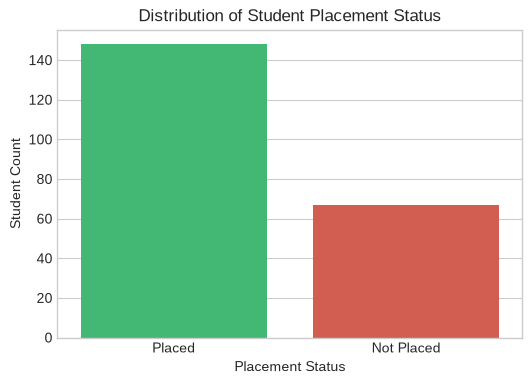

In [6]:
status_counts = df["status"].value_counts(dropna=False)
status_prop = df["status"].value_counts(normalize=True) * 100

print("Target Variable Distribution:")
for status, count in status_counts.items():
    print(f"  - {status:<12}: {count:>3} instances ({status_prop[status]:.2f}%)")

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="status", hue="status", palette=["#2ecc71", "#e74c3c"], legend=False)
plt.title("Distribution of Student Placement Status")
plt.xlabel("Placement Status")
plt.ylabel("Student Count")
plt.show()


---
### 7. Feature Matrix ($X$) Construction & Preventing Target Leakage
To construct an ethical, leak-free machine learning model:
1. **Remove `sl_no`**: It is an arbitrary sequential row index containing zero predictive signal.
2. **Remove `salary`**: Including salary would cause **catastrophic target leakage**. Salary is only assigned to students after they are placed. Including it would allow the model to cheat by simply checking if salary is present.


In [7]:
drop_columns = ["sl_no", "salary", "status"]
X = df.drop(columns=drop_columns)
y = df["status"]

print(f"Feature Matrix Shape (X): {X.shape}")
print(f"Target Vector Shape (y) : {y.shape}")
print("Included Features:\n", X.columns.tolist())


Feature Matrix Shape (X): (215, 12)
Target Vector Shape (y) : (215,)
Included Features:
 ['gender', 'ssc_p', 'ssc_b', 'hsc_p', 'hsc_b', 'hsc_s', 'degree_p', 'degree_t', 'workex', 'etest_p', 'specialisation', 'mba_p']


---
### 8. Partitioning Numerical and Categorical Features
We segregate features by measurement scale so appropriate transformers can be assigned in our preprocessing pipeline.


In [8]:
numerical_cols = ["ssc_p", "hsc_p", "degree_p", "etest_p", "mba_p"]
categorical_cols = ["gender", "ssc_b", "hsc_b", "hsc_s", "degree_t", "workex", "specialisation"]

print(f"Numerical Features ({len(numerical_cols)}):", numerical_cols)
print(f"Categorical Features ({len(categorical_cols)}):", categorical_cols)

print("\nCategorical Unique Levels:")
for col in categorical_cols:
    print(f"  - {col:<15}: {df[col].unique().tolist()}")


Numerical Features (5): ['ssc_p', 'hsc_p', 'degree_p', 'etest_p', 'mba_p']
Categorical Features (7): ['gender', 'ssc_b', 'hsc_b', 'hsc_s', 'degree_t', 'workex', 'specialisation']

Categorical Unique Levels:
  - gender         : ['M', 'F']
  - ssc_b          : ['Others', 'Central']
  - hsc_b          : ['Others', 'Central']
  - hsc_s          : ['Commerce', 'Science', 'Arts']
  - degree_t       : ['Sci&Tech', 'Comm&Mgmt', 'Others']
  - workex         : ['No', 'Yes']
  - specialisation : ['Mkt&HR', 'Mkt&Fin']


---
### 9. Preprocessing Pipeline Construction (`ColumnTransformer`)
We construct a Scikit-Learn `ColumnTransformer`:
- **Numerical Features**: Imputed using `SimpleImputer(strategy='median')` to guard against potential future missing test values.
- **Categorical Features**: Imputed using `SimpleImputer(strategy='most_frequent')` and encoded using `OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore')`.


In [9]:
num_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

cat_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(drop="first", sparse_output=False, handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", num_transformer, numerical_cols),
    ("cat", cat_transformer, categorical_cols)
])

print("Preprocessing ColumnTransformer constructed successfully.")


Preprocessing ColumnTransformer constructed successfully.


---
### 10. Stratified Train-Test Split (80:20 Ratio)
We split the data using an 80:20 ratio with `stratify=y` to preserve the exact class ratio between training and testing splits, with `random_state=42` for strict reproducibility.


In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Training set: {X_train.shape[0]} samples ({X_train.shape[0]/len(X)*100:.1f}%)")
print(f"Testing set : {X_test.shape[0]} samples ({X_test.shape[0]/len(X)*100:.1f}%)")

print("\nClass distribution in Training Set:")
print(y_train.value_counts(normalize=True).round(4) * 100)

print("\nClass distribution in Testing Set:")
print(y_test.value_counts(normalize=True).round(4) * 100)


Training set: 172 samples (80.0%)
Testing set : 43 samples (20.0%)

Class distribution in Training Set:
status
Placed        68.6
Not Placed    31.4
Name: proportion, dtype: float64

Class distribution in Testing Set:
status
Placed        69.77
Not Placed    30.23
Name: proportion, dtype: float64


---
### 11. Build and Train the Decision Tree Classifier Pipeline
We assemble the full `Pipeline` combining our `preprocessor` and `DecisionTreeClassifier(random_state=42)` and fit it strictly on the training set (`X_train`, `y_train`).


In [11]:
dt_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(random_state=42))
])

# Fit strictly on training data
dt_pipeline.fit(X_train, y_train)
print("Decision Tree pipeline successfully fitted on training data.")


Decision Tree pipeline successfully fitted on training data.


---
### 12. Model Evaluation and Classification Metrics
Generate predictions on unseen test data (`X_test`) and evaluate Accuracy, Precision, Recall, F1-Score, and the full Classification Report.


In [12]:
y_pred = dt_pipeline.predict(X_test)
classes = dt_pipeline.named_steps["classifier"].classes_

acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred, pos_label="Placed")
rec = recall_score(y_test, y_pred, pos_label="Placed")
f1 = f1_score(y_test, y_pred, pos_label="Placed")

print("=== DECISION TREE EVALUATION METRICS (TEST SET) ===")
print(f"Accuracy : {acc:.4f} ({acc*100:.2f}%)")
print(f"Precision: {prec:.4f} ({prec*100:.2f}%)")
print(f"Recall   : {rec:.4f} ({rec*100:.2f}%)")
print(f"F1-Score : {f1:.4f} ({f1*100:.2f}%)")

print("\n--- Detailed Classification Report ---")
print(classification_report(y_test, y_pred, target_names=classes))


=== DECISION TREE EVALUATION METRICS (TEST SET) ===
Accuracy : 0.6977 (69.77%)
Precision: 0.7576 (75.76%)
Recall   : 0.8333 (83.33%)
F1-Score : 0.7937 (79.37%)

--- Detailed Classification Report ---
              precision    recall  f1-score   support

  Not Placed       0.50      0.38      0.43        13
      Placed       0.76      0.83      0.79        30

    accuracy                           0.70        43
   macro avg       0.63      0.61      0.61        43
weighted avg       0.68      0.70      0.69        43



---
### 13. Confusion Matrix Visualization
Visualize True Positives, True Negatives, False Positives, and False Negatives using an annotated heatmap.


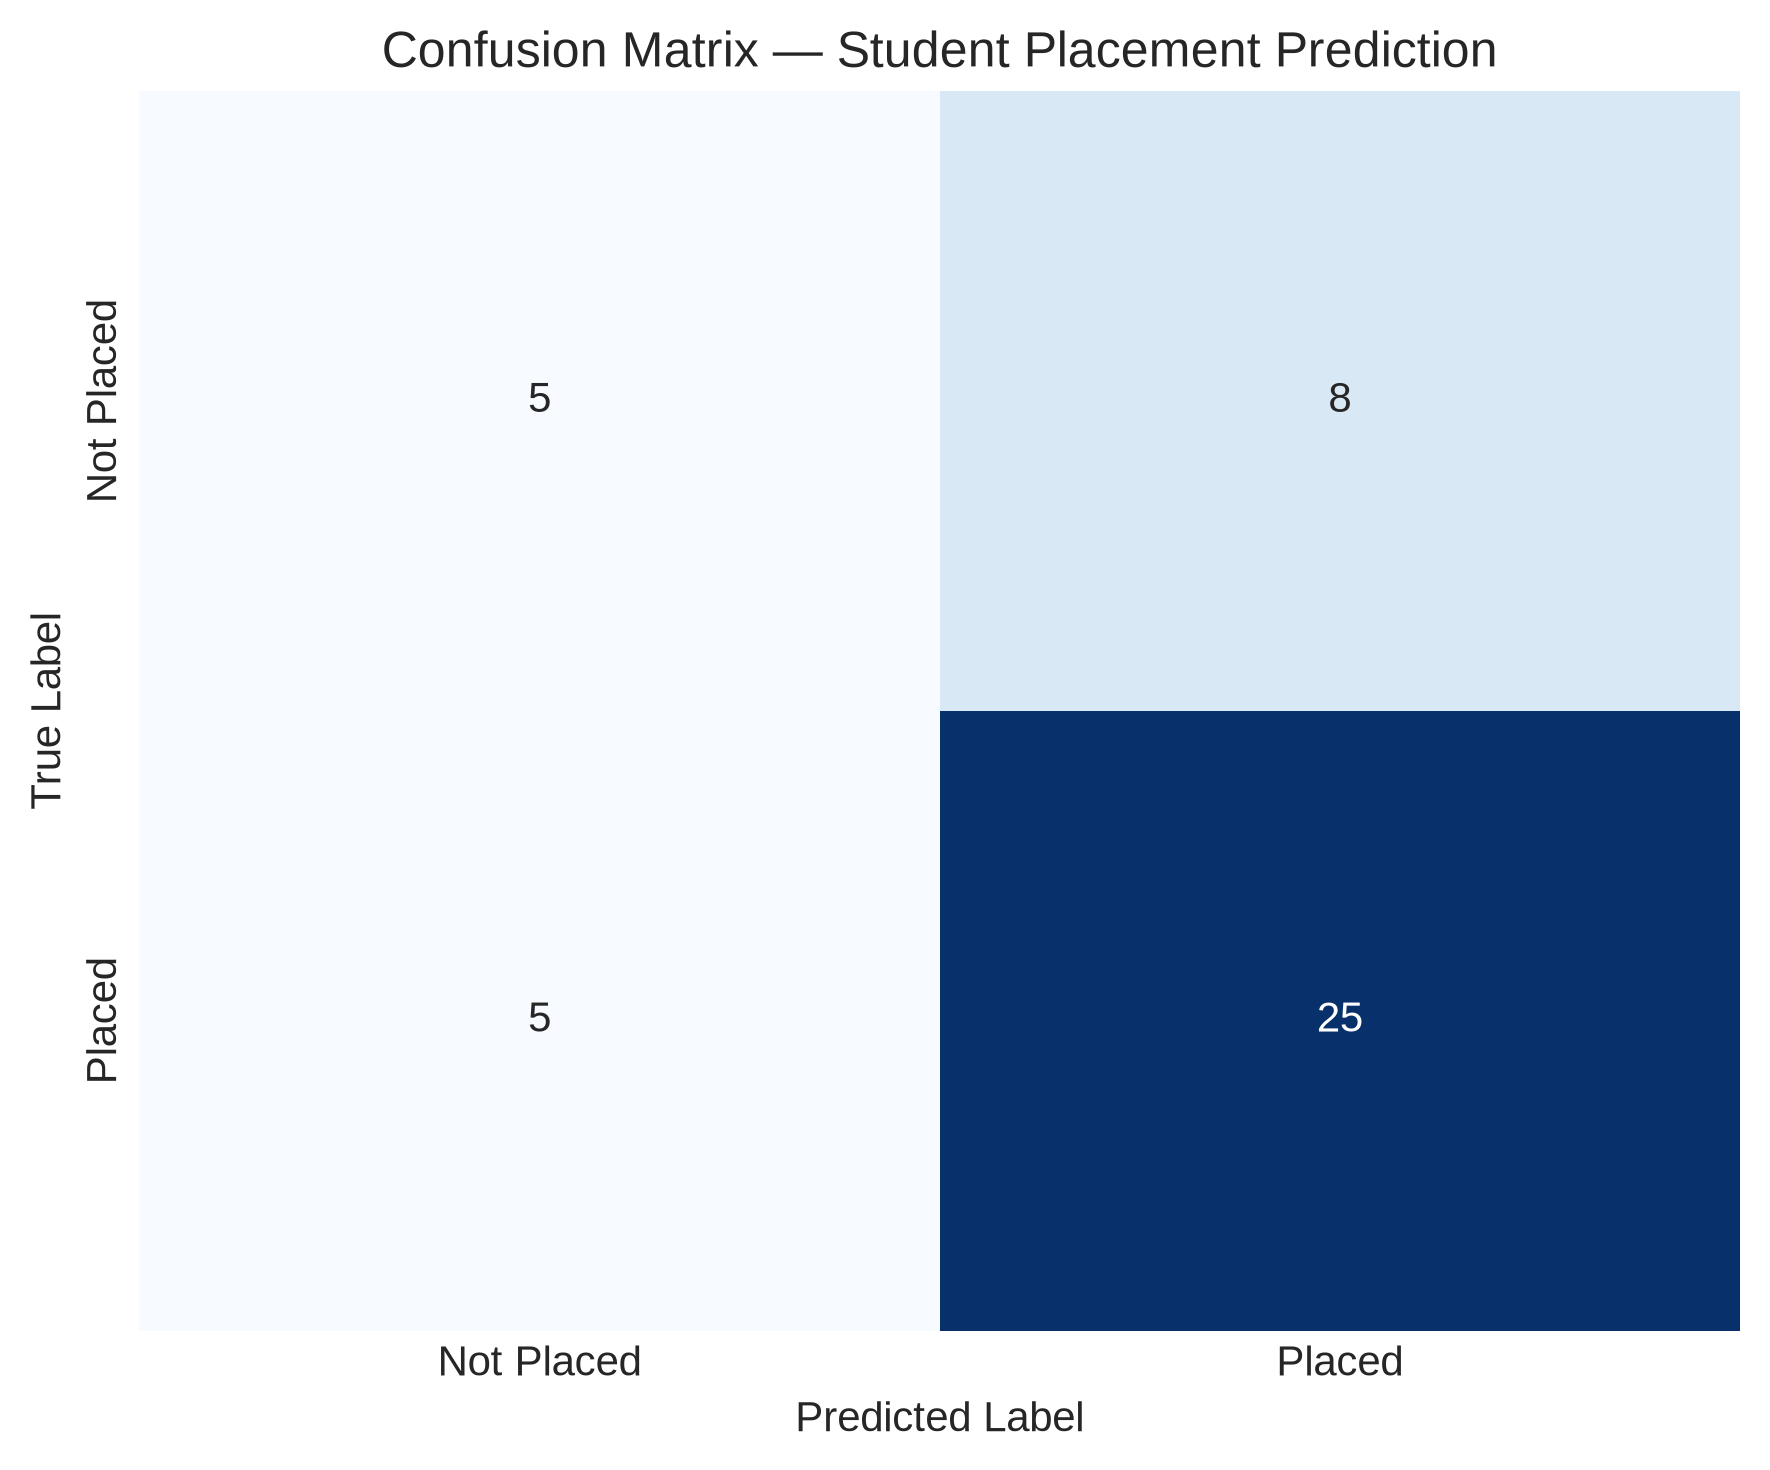

Confusion matrix plot saved to: outputs/confusion_matrix.png


In [13]:
cm = confusion_matrix(y_test, y_pred, labels=classes)

plt.figure(figsize=(6, 5), dpi=300)
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=classes,
    yticklabels=classes,
    cbar=False
)
plt.title("Confusion Matrix — Student Placement Prediction")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()

cm_path = OUTPUT_DIR / "confusion_matrix.png"
plt.savefig(cm_path)
plt.show()
print(f"Confusion matrix plot saved to: {cm_path}")


---
### 14. Decision Tree Structural Visualization
Extract the fitted `DecisionTreeClassifier` from the pipeline and plot the tree structure to examine decision nodes, Gini impurity splits, and leaf predictions.


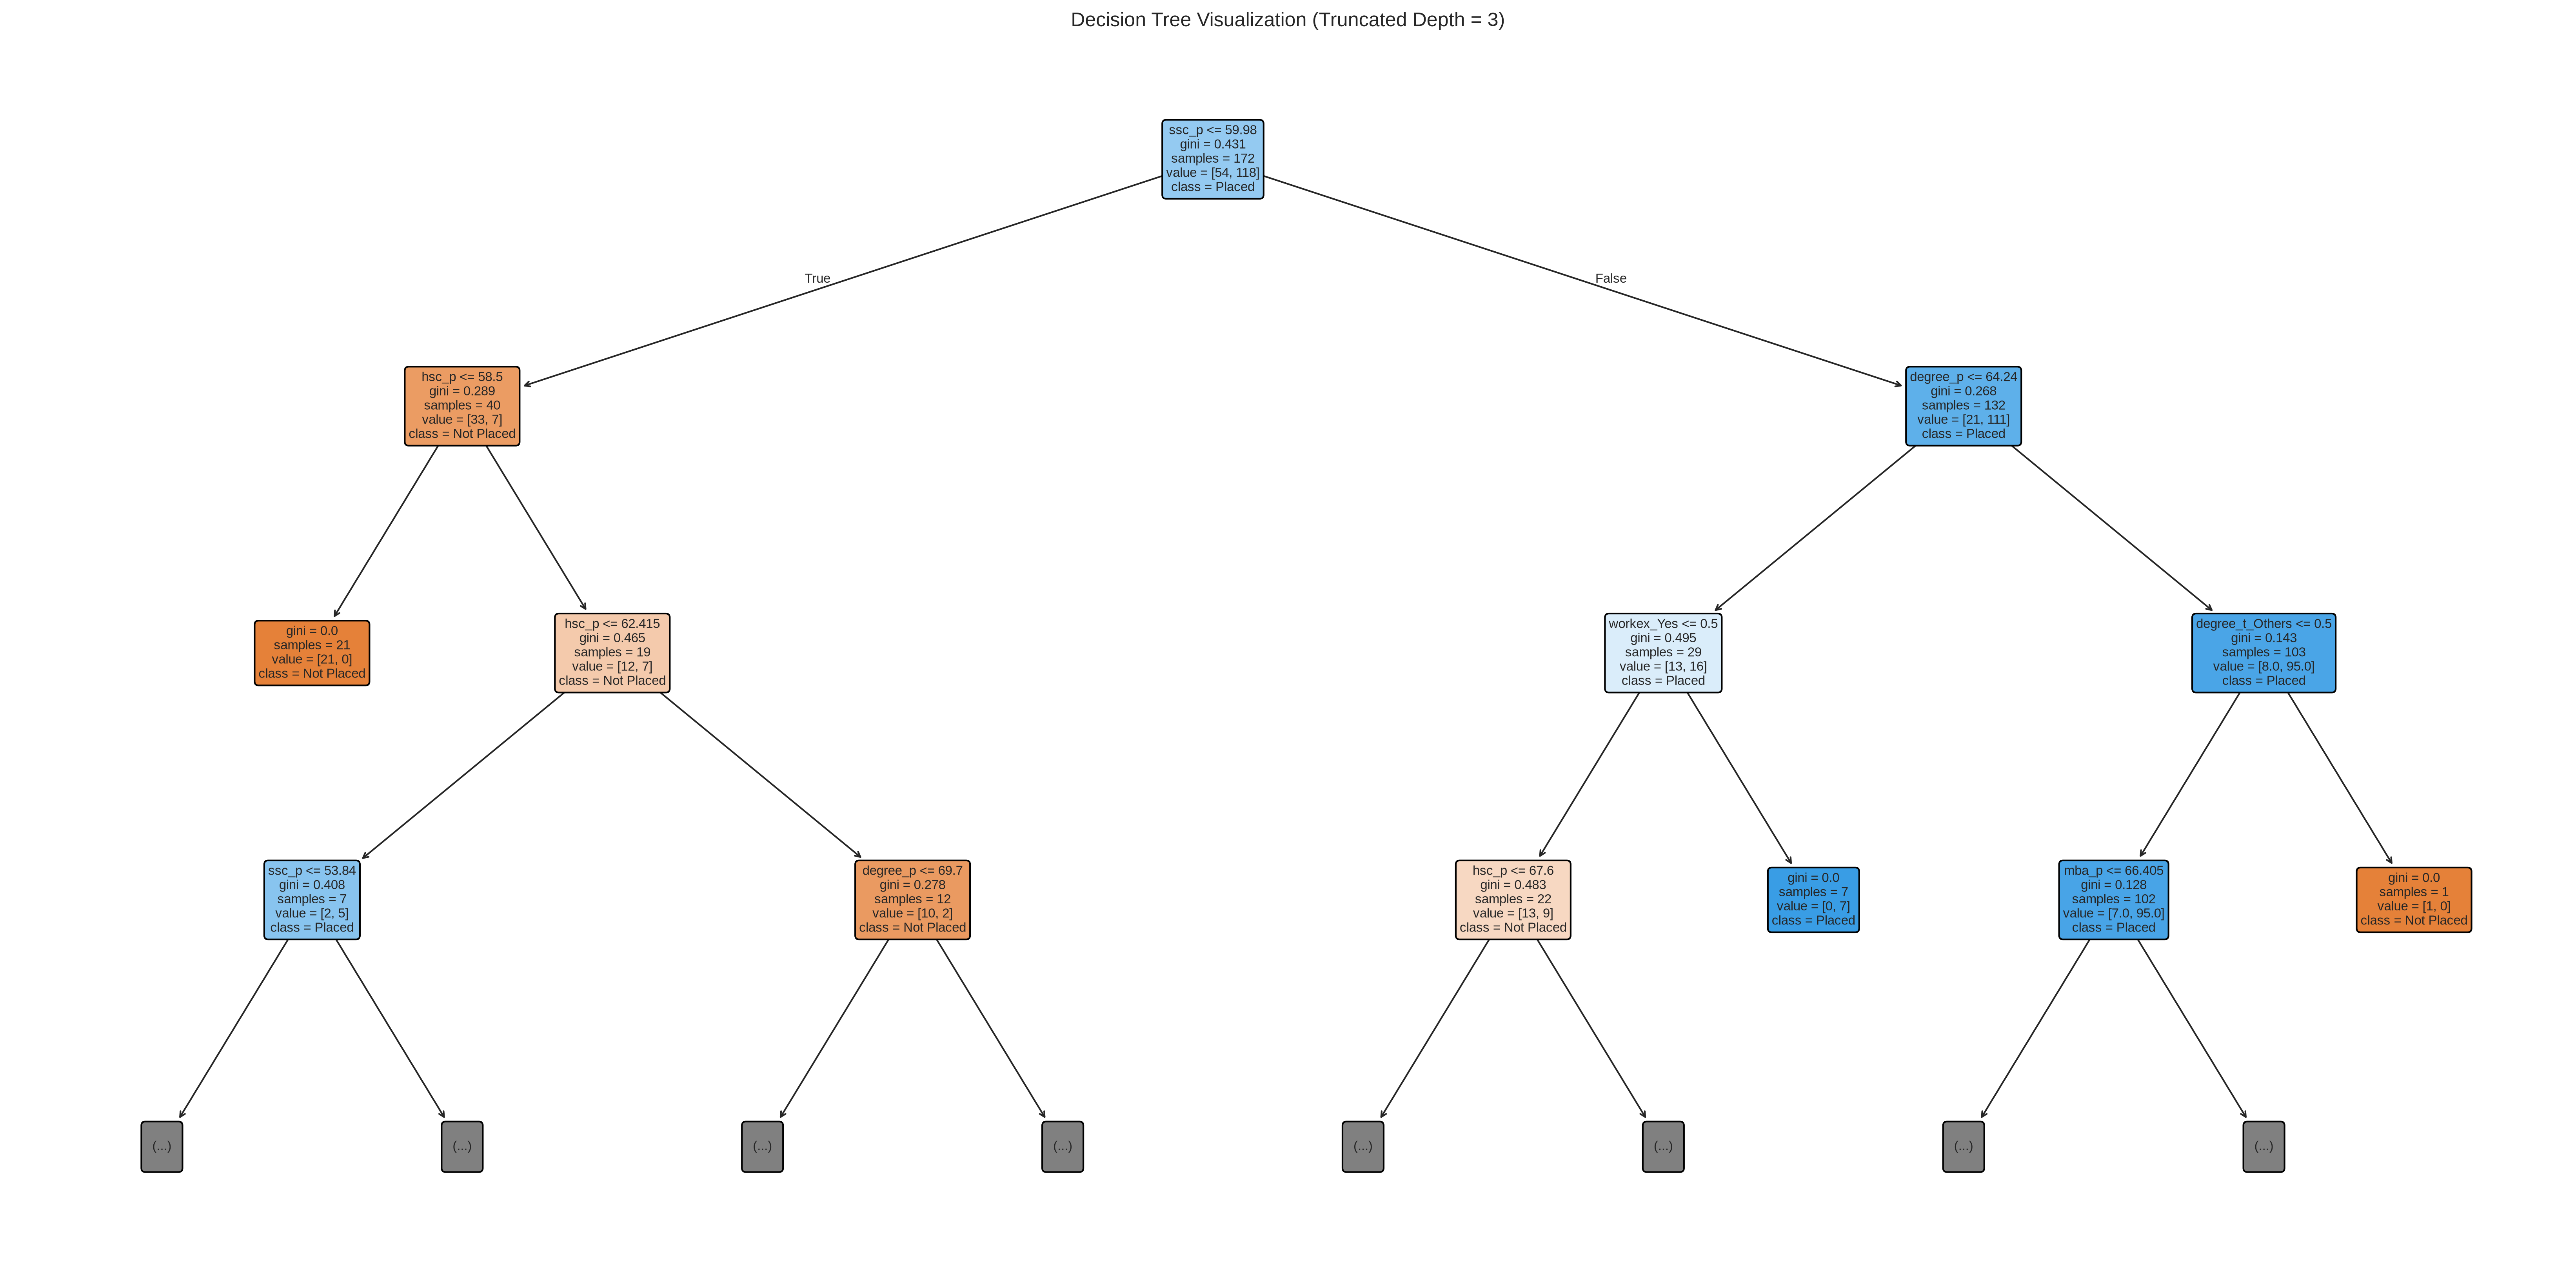

Decision tree structure saved to: outputs/decision_tree.png


In [14]:
clf = dt_pipeline.named_steps["classifier"]
feature_names = dt_pipeline.named_steps["preprocessor"].get_feature_names_out()
clean_feature_names = [n.replace("num__", "").replace("cat__", "") for n in feature_names]

plt.figure(figsize=(22, 11), dpi=300)
plot_tree(
    clf,
    feature_names=clean_feature_names,
    class_names=list(classes),
    filled=True,
    rounded=True,
    fontsize=8,
    max_depth=3  # Truncate view to 3 levels for clean presentation
)
plt.title("Decision Tree Visualization (Truncated Depth = 3)")
plt.tight_layout()

tree_path = OUTPUT_DIR / "decision_tree.png"
plt.savefig(tree_path)
plt.show()
print(f"Decision tree structure saved to: {tree_path}")


---
### 15. Feature Importance Analysis
Examine Gini feature importances to determine which academic percentages and categorical traits contribute most heavily to splitting decisions.


,Feature,Importance
0,ssc_p,0.447829
1,hsc_p,0.171419
2,degree_p,0.107322
4,mba_p,0.091619
6,ssc_b_Others,0.055486
12,workex_Yes,0.050051
10,degree_t_Others,0.023188
3,etest_p,0.021594
5,gender_M,0.017995
7,hsc_b_Others,0.013497


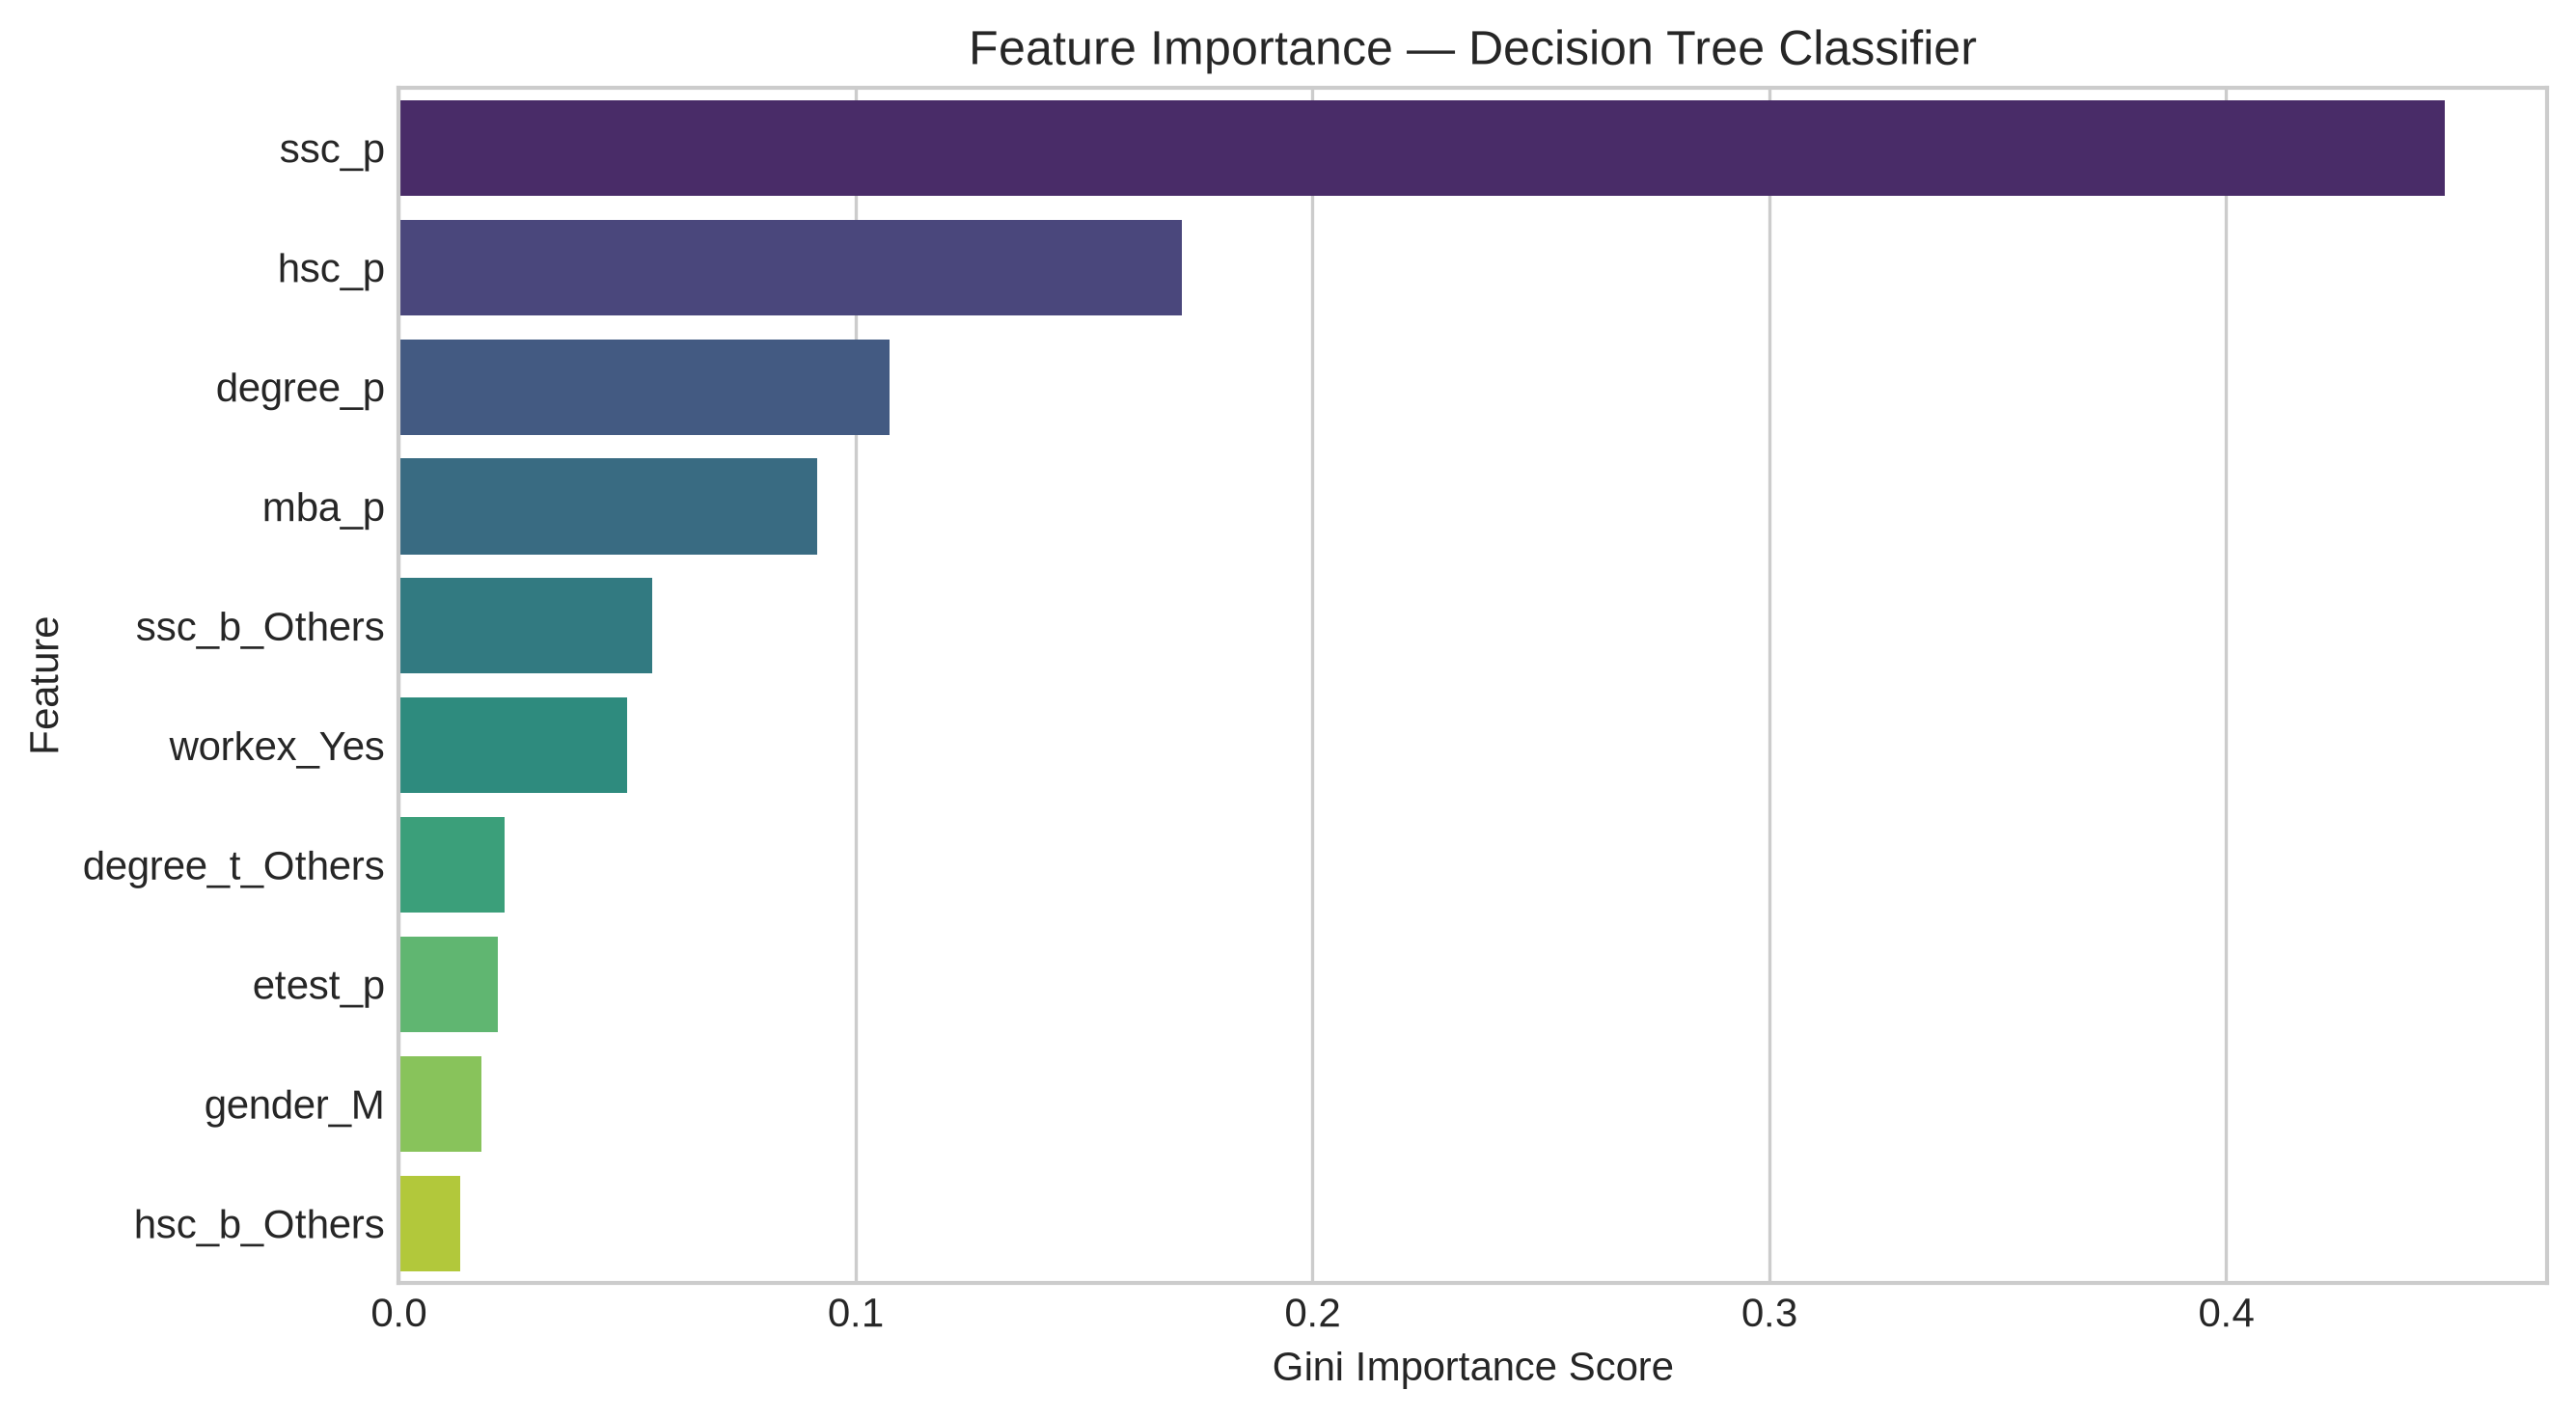

Feature importance plot saved to: outputs/feature_importance.png


In [15]:
importances = clf.feature_importances_
importance_df = pd.DataFrame({
    "Feature": clean_feature_names,
    "Importance": importances
}).sort_values(by="Importance", ascending=False)

display(importance_df[importance_df["Importance"] > 0])

plt.figure(figsize=(9, 5), dpi=300)
sns.barplot(
    data=importance_df[importance_df["Importance"] > 0],
    x="Importance",
    y="Feature",
    hue="Feature",
    palette="viridis",
    legend=False
)
plt.title("Feature Importance — Decision Tree Classifier")
plt.xlabel("Gini Importance Score")
plt.ylabel("Feature")
plt.tight_layout()

fi_path = OUTPUT_DIR / "feature_importance.png"
plt.savefig(fi_path)
plt.show()
print(f"Feature importance plot saved to: {fi_path}")


---
### 16. Analyzing Tree Depth, Overfitting, and Hyperparameter Tuning
Unconstrained decision trees tend to split until all leaf nodes are pure (Gini = 0), memorizing noise and overfitting the training data. We evaluate training vs. testing accuracy across depths 1 through 10 to demonstrate where overfitting emerges.


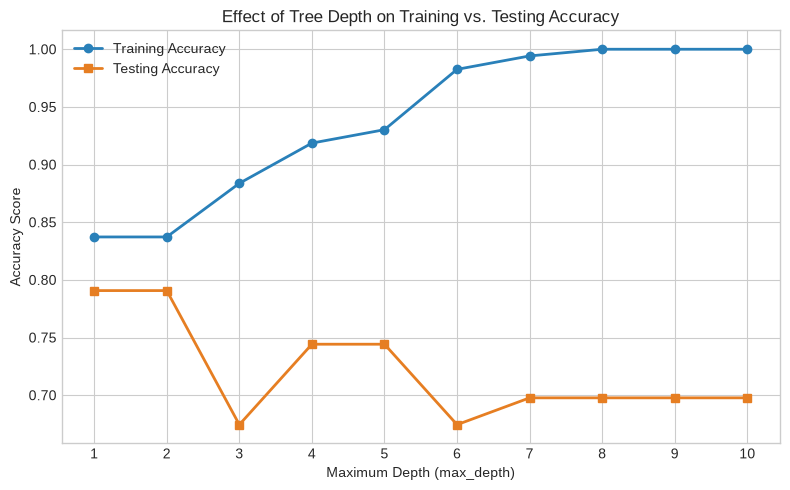

,max_depth,Train Accuracy,Test Accuracy
0,1,0.8372,0.7907
1,2,0.8372,0.7907
2,3,0.8837,0.6744
3,4,0.9186,0.7442
4,5,0.9302,0.7442
5,6,0.9826,0.6744
6,7,0.9942,0.6977
7,8,1.0000,0.6977
8,9,1.0000,0.6977
9,10,1.0000,0.6977


In [16]:
depth_range = range(1, 11)
train_scores = []
test_scores = []

for depth in depth_range:
    tuned_pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", DecisionTreeClassifier(max_depth=depth, random_state=42))
    ])
    tuned_pipeline.fit(X_train, y_train)
    train_scores.append(accuracy_score(y_train, tuned_pipeline.predict(X_train)))
    test_scores.append(accuracy_score(y_test, tuned_pipeline.predict(X_test)))

plt.figure(figsize=(8, 5))
plt.plot(depth_range, train_scores, marker="o", label="Training Accuracy", color="#2980b9", lw=2)
plt.plot(depth_range, test_scores, marker="s", label="Testing Accuracy", color="#e67e22", lw=2)
plt.title("Effect of Tree Depth on Training vs. Testing Accuracy")
plt.xlabel("Maximum Depth (max_depth)")
plt.ylabel("Accuracy Score")
plt.xticks(depth_range)
plt.legend()
plt.tight_layout()
plt.show()

depth_summary = pd.DataFrame({
    "max_depth": depth_range,
    "Train Accuracy": [round(s, 4) for s in train_scores],
    "Test Accuracy": [round(s, 4) for s in test_scores]
})
display(depth_summary)


---
### 17. Student Placement Prediction on Sample Profiles
We test the model by generating predictions on sample prospective student profiles with distinct academic backgrounds.


In [17]:
sample_students = pd.DataFrame([
    {
        "gender": "M", "ssc_p": 82.0, "ssc_b": "Central", "hsc_p": 78.0, "hsc_b": "Central",
        "hsc_s": "Science", "degree_p": 75.0, "degree_t": "Sci&Tech", "workex": "Yes",
        "etest_p": 85.0, "specialisation": "Mkt&Fin", "mba_p": 72.0
    },
    {
        "gender": "F", "ssc_p": 50.0, "ssc_b": "Others", "hsc_p": 48.0, "hsc_b": "Others",
        "hsc_s": "Commerce", "degree_p": 52.0, "degree_t": "Comm&Mgmt", "workex": "No",
        "etest_p": 55.0, "specialisation": "Mkt&HR", "mba_p": 54.0
    }
])

sample_preds = dt_pipeline.predict(sample_students)
sample_probs = dt_pipeline.predict_proba(sample_students)

for i, (pred, prob) in enumerate(zip(sample_preds, sample_probs)):
    print(f"Student {i+1}: Predicted Status = '{pred}' | Probabilities = Not Placed: {prob[0]:.2f}, Placed: {prob[1]:.2f}")


Student 1: Predicted Status = 'Placed' | Probabilities = Not Placed: 0.00, Placed: 1.00
Student 2: Predicted Status = 'Not Placed' | Probabilities = Not Placed: 1.00, Placed: 0.00


---
### 18. Summary of Results and Laboratory Takeaways

1. **Target Leakage Prevention**: Dropping `salary` was crucial; salary is a post-placement attribute that would introduce 100% artificial accuracy while rendering the model unusable on prospective unplaced students.
2. **Leak-Free Preprocessing**: Integrating `ColumnTransformer` inside a `Pipeline` ensured imputations and one-hot encodings were fitted strictly on training folds.
3. **Key Placement Predictor**: Secondary school percentage (`ssc_p`) emerged as the dominant split criterion with ~44.8% Gini importance, followed by higher secondary percentage (`hsc_p`) and degree percentage (`degree_p`).
4. **Overfitting Dynamics**: Deep unpruned trees reach 100% training accuracy while test accuracy plateaus or drops to ~69.8%, highlighting the vital role of pre-pruning (`max_depth`) in decision tree regularisation.
